# Salary Prediction

## Objective

The objective of this notebook is to build machine learning models that predict the average annual salary of data-related jobs based on job characteristics and technical skills extracted from job description.

The models are also used to identify the factors that have the greatest influence on salary prediction.

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

### Load Processed Dataset

Load the processed dataset containing the cleaned job information and the technical skill features extracted in the previous notebook.

In [2]:
df = pd.read_csv('../data/processed/data_jobs_with_skills.csv')

In [3]:
df.columns

Index(['Job Title', 'Salary Estimate', 'Job Description', 'Rating',
       'Company Name', 'Location', 'Headquarters', 'Size', 'Founded',
       'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Competitors',
       'Easy Apply', 'Min Salary (K)', 'Max Salary (K)', 'Average Salary (K)',
       'Job Category', 'Seniority', 'Is Core Data Role', 'sql', 'python',
       'statistics', 'machine learning', 'data analysis', 'big data',
       'data analytics', 'business intelligence', 'data visualization',
       'data mining', 'data pipelines', 'data engineering', 'data management',
       'data modeling', 'deep learning', 'software development',
       'statistical analysis', 'advanced analytics',
       'natural language processing'],
      dtype='str')

### Filter Core Data Roles

The dataset contains both data-related and non-data-related job postings.

Since the objective of this project is to predict salaries for data professionals, only core data roles are retained for modeling.

Non-data-related positions are removed to make the prediction task more consistent and interpretable.

In [4]:
df_data_core = df[df['Is Core Data Role']].copy()

In [5]:
df_data_core.shape

(3829, 40)

### Define Target Variable

The target variable is the average annual salary.

In [6]:
target = 'Average Salary (K)'

X = df_data_core.drop(target, axis=1)
y = df_data_core[target]

In [7]:
X.columns

Index(['Job Title', 'Salary Estimate', 'Job Description', 'Rating',
       'Company Name', 'Location', 'Headquarters', 'Size', 'Founded',
       'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Competitors',
       'Easy Apply', 'Min Salary (K)', 'Max Salary (K)', 'Job Category',
       'Seniority', 'Is Core Data Role', 'sql', 'python', 'statistics',
       'machine learning', 'data analysis', 'big data', 'data analytics',
       'business intelligence', 'data visualization', 'data mining',
       'data pipelines', 'data engineering', 'data management',
       'data modeling', 'deep learning', 'software development',
       'statistical analysis', 'advanced analytics',
       'natural language processing'],
      dtype='str')

In [8]:
y.head()

0    146
1    146
2    146
3    146
4    146
Name: Average Salary (K), dtype: int64

### Remove Unnecessary Features

Some columns are plain text or contain direct information about average salary so they are not useful for modeling therefore they are removed.

In [9]:
remove_columns = [
    'Is Core Data Role',
    'Min Salary (K)',
    'Max Salary (K)',
    'Salary Estimate',
    'Job Description',
    'Job Title',
    'Company Name'
]

In [10]:
X = X.drop(remove_columns, axis=1)

In [11]:
X.columns

Index(['Rating', 'Location', 'Headquarters', 'Size', 'Founded',
       'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Competitors',
       'Easy Apply', 'Job Category', 'Seniority', 'sql', 'python',
       'statistics', 'machine learning', 'data analysis', 'big data',
       'data analytics', 'business intelligence', 'data visualization',
       'data mining', 'data pipelines', 'data engineering', 'data management',
       'data modeling', 'deep learning', 'software development',
       'statistical analysis', 'advanced analytics',
       'natural language processing'],
      dtype='str')

### Check Missing Value

Missing values are examined before preprocessing.

Columns with excessive missing values will be reviewed and either removed or handled during preprocessing.

In [12]:
X.isna().sum().sort_values(ascending=False)

Easy Apply                     3668
Competitors                    2715
Founded                         962
Industry                        537
Sector                          537
Rating                          400
Headquarters                    233
Size                            222
Revenue                         222
Type of ownership               222
Location                          0
Job Category                      0
Seniority                         0
sql                               0
python                            0
statistics                        0
machine learning                  0
data analysis                     0
big data                          0
data analytics                    0
business intelligence             0
data visualization                0
data mining                       0
data pipelines                    0
data engineering                  0
data management                   0
data modeling                     0
deep learning               

In [13]:
X = X.drop(['Easy Apply', 'Competitors'], axis=1)

### Create Company Age Feature

The founding year of a company will be transformed into company age.

Since the dataset was collected around 2020, it is used as the reference year to calculate company age.

Company Age = 2020 - Founded

In [14]:
reference_year = 2020
X['Company Age'] = reference_year - X['Founded']

In [15]:
X[['Founded', 'Company Age']].head()

,Founded,Company Age
0,2007.0,13.0
1,2008.0,12.0
2,NaN,NaN
3,2019.0,1.0
4,2007.0,13.0


In [16]:
X = X.drop('Founded', axis=1)

### Identify Feature Types

The dataset contains different preprocessing steps.

- Numerical features
- Categorical features
- Binary features

In [17]:
X.info()

<class 'pandas.DataFrame'>
Index: 3829 entries, 0 to 3908
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Rating                       3429 non-null   float64
 1   Location                     3829 non-null   str    
 2   Headquarters                 3596 non-null   str    
 3   Size                         3607 non-null   str    
 4   Type of ownership            3607 non-null   str    
 5   Industry                     3292 non-null   str    
 6   Sector                       3292 non-null   str    
 7   Revenue                      3607 non-null   str    
 8   Job Category                 3829 non-null   str    
 9   Seniority                    3829 non-null   str    
 10  sql                          3829 non-null   bool   
 11  python                       3829 non-null   bool   
 12  statistics                   3829 non-null   bool   
 13  machine learning             3829 

In [18]:
numerical_features = X.select_dtypes(include='number').columns.tolist()
categorical_features = X.select_dtypes(include='string').columns.tolist()
binary_features = X.select_dtypes(include='bool').columns.tolist()

In [19]:
print('Numerical')
print(numerical_features)
print()
print('Categorical')
print(categorical_features)
print()
print('Binary')
print(binary_features)
print()

Numerical
['Rating', 'Company Age']

Categorical
['Location', 'Headquarters', 'Size', 'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Job Category', 'Seniority']

Binary
['sql', 'python', 'statistics', 'machine learning', 'data analysis', 'big data', 'data analytics', 'business intelligence', 'data visualization', 'data mining', 'data pipelines', 'data engineering', 'data management', 'data modeling', 'deep learning', 'software development', 'statistical analysis', 'advanced analytics', 'natural language processing']



### Encode Binary skill Features

Technical skills are currently stored as boolean values.

They are converted into numerical binary features:
- True: 1
- False: 0

This representation is suitable for machine learning algorithms.

In [20]:
X[binary_features] = X[binary_features].astype(int)

In [21]:
X[binary_features].head()

,sql,python,statistics,machine learning,data analysis,big data,data analytics,business intelligence,data visualization,data mining,data pipelines,data engineering,data management,data modeling,deep learning,software development,statistical analysis,advanced analytics,natural language processing
0,1,0,1,1,0,1,0,1,1,1,0,0,0,0,0,0,0,0,0
1,1,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0
2,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,1,1,0,0,0,0,0,1,1,0,0,0,1,0,0,0,0,0,0
4,0,1,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0


## Create Preprocessing Pipelines

Different preprocessing steps are applied to different feature groups.

Numerical features:
- Missing values are replaced using the median.
- Features are scaled using StandardScaler.

Categorical features:
- Missing values are replaced using 'Unknown'.
- Categories are transformed using OneHot Encoding.

Binary Skill features:
- Already converted into numerical 0/1 values and passed directly to the model.

In [22]:
numerical_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

In [23]:
categorical_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [24]:
preprocessor = ColumnTransformer(
    transformers=[
        ('numerical', numerical_pipeline, numerical_features),
        ('categorical', categorical_pipeline, categorical_features),
        ('binary', 'passthrough', binary_features),
    ]
)

### Split Data

The dataset is divided into training and testing sets.

The training set is used to learn patterns from the data, while the test set is used to evaluate how well the model performs on unseen job postings.

20% of the data is reserved for testing.

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Baseline Model: Linear Regression

Linear Regression is used as a baseline model.

It provides a simple reference point to understand how well salary can be predicted using a linear relationship between job features and salary.

In [26]:
linear_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LinearRegression())
    ]
)

In [27]:
linear_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['Rating','Location','Headquarters',...,'advanced analytics', 'natural language processing','Company Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will b

In [28]:
y_pred = linear_model.predict(X_test)

### Model Evaluation

The model is evaluated using:

- MAE: Average absolute difference between predicted and actual salary.
- RMSE: Penalizes larger prediction errors.
- R2: Measures how much variance in salary is explained by the model.

In [29]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

In [30]:
print(f'MAE: {mae:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'R2: {r2:.2f}')

MAE: 27.32
RMSE: 35.01
R2: 0.15


## Random Forest Regressor

Random Forest is an ensemble learning algorithm that combines multiple decision trees.

Unlike linear models, it can capture complex and non-linear relationships between job characteristics and salary.

In [31]:
rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', RandomForestRegressor(random_state=42))
    ]
)

In [32]:
rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['Rating','Location','Headquarters',...,'advanced analytics', 'natural language processing','Company Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will b

In [33]:
y_pred = rf_model.predict(X_test)

### Model Evaluation

The model is evaluated using:

- MAE: Average absolute difference between predicted and actual salary.
- RMSE: Penalizes larger prediction errors.
- R2: Measures how much variance in salary is explained by the model.

In [34]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

In [35]:
print(f'MAE: {mae:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'R2: {r2:.2f}')

MAE: 24.62
RMSE: 31.70
R2: 0.30


### Hyperparameter Tuning

The default Random Forest model is optimized using RandomSearchCV.

Different combinations of hyperparameters are evaluated using cross-validation to improve the model's predictive performance while reducing overfitting.

Randomized Search is used with 5-fold cross-validation to search for a better combination of Random Forest hyperparameter.

The best model is selected based on the lowest prediction error across the validation folds.

In [37]:
param_grid = {
    'model__n_estimators': [100, 200, 300, 500],
    'model__max_depth': [None, 10, 20, 30],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 'log2']
}

In [38]:
random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_grid,
    n_iter=30,
    cv=5,
    scoring='neg_mean_squared_error',
    random_state=42
)

In [39]:
random_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': [None, 10, ...], 'model__max_features': ['sqrt', 'log2'], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` direc

In [40]:
random_search.best_params_

{'model__n_estimators': 200,
 'model__min_samples_split': 10,
 'model__min_samples_leaf': 1,
 'model__max_features': 'sqrt',
 'model__max_depth': None}

In [41]:
random_search.best_score_

np.float64(-1051.0191241925381)

In [42]:
best_rf = random_search.best_estimator_

In [43]:
y_pred_best = best_rf.predict(X_test)

In [44]:
mae = mean_absolute_error(y_test, y_pred_best)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_best))
r2 = r2_score(y_test, y_pred_best)

In [45]:
print(f'MAE: {mae:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'R2: {r2:.2f}')

MAE: 25.63
RMSE: 31.89
R2: 0.29


### Hyperparameter Tuning Results

Although the tuned model achieved competitive performance during cross-validation, it did not outperform the default Random Forest model on the test set.

Therefore, the default Random Forest model was selected as the final model for further interpretation.

### Feature Importance

Feature importance is used to identify which variables contributed the most to the Random Forest predictions.

The importance scores indicates how much each feature helped reduce prediction error across all decision trees.

Since the predictive performance of the model is moderate, the importance of the model is moderate, the importance values should be interpreted as model-specific insights rather than definitive evidence of casual relationships.

In [54]:
rf_importance = rf_model.named_steps['model'].feature_importances_
feature_names = rf_model.named_steps['preprocessor'].get_feature_names_out()

In [65]:
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_importance
})

In [66]:
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)
feature_importance.head()

,Feature,Importance
820,categorical__Job Category_Data Scientist,0.055164
132,"categorical__Location_San Jose, CA",0.051259
1,numerical__Company Age,0.046154
0,numerical__Rating,0.040459
133,"categorical__Location_Santa Clara, CA",0.038193


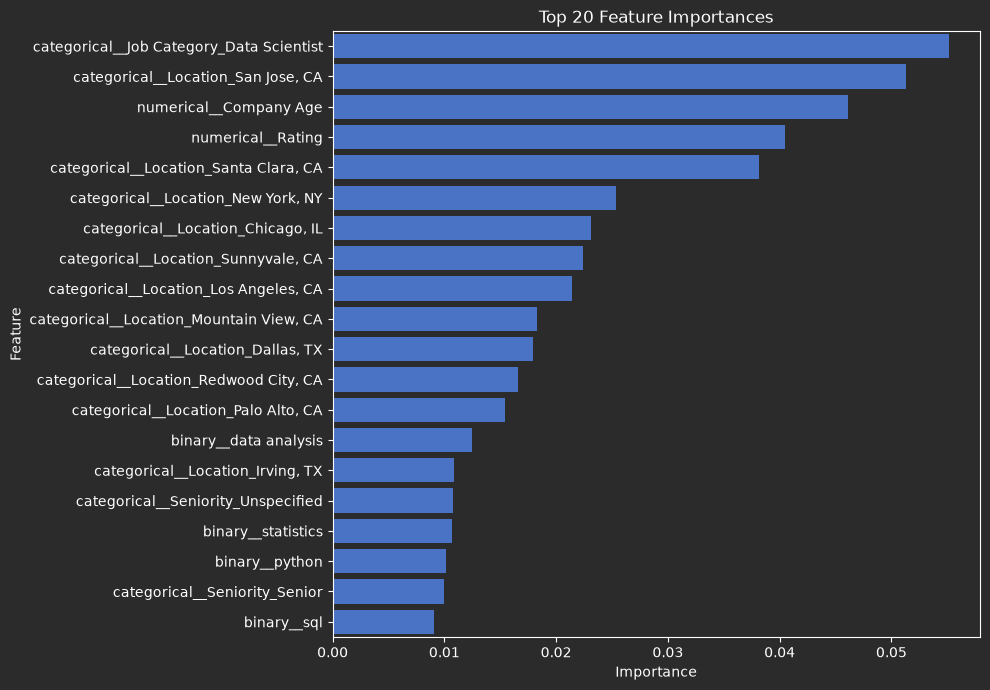

In [60]:
plt.figure(figsize=(10, 7))
sns.barplot(
    data=feature_importance.head(20),
    x='Importance',
    y='Feature'
)
plt.title('Top 20 Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# Model Evaluation and Interpretation

## Model Comparison

Three different approaches were evaluated for salary prediction:

- Linear Regression as a baseline model
- Random Forest Regressor
- Tuned Random Forest using RandomizedSearchCV

The models were compared using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² score.

| Model | MAE (K) | RMSE (K) | R² |
|---|---:|---:|---:|
| Linear Regression | 27.32 | 35.01 | 0.15 |
| Random Forest | 24.62 | 31.70 | 0.30 |
| Tuned Random Forest | 25.63 | 31.89 | 0.29 |

The Random Forest model achieved the best performance on the test set, reducing prediction error compared with the linear baseline.

Although hyperparameter tuning improved the model configuration, it did not improve performance on the test set. Therefore, the default Random Forest model was selected as the final model.

## Feature Importance Analysis

Feature importance was analyzed using the final Random Forest model to understand which variables contributed most to salary predictions.

The most influential features were:

1. Job Category (especially Data Scientist)
2. Location-related features
3. Company Age
4. Company Rating
5. Technical skills such as data analysis, statistics, Python, and SQL

Location and job category had a stronger contribution than individual technical skills.

This suggests that salary differences in data-related roles are influenced not only by technical requirements but also by job type and geographic market conditions.

## Limitations

The final model achieved an R² score of approximately 0.30, meaning that a significant portion of salary variation remains unexplained.

Possible reasons include:

- Missing information about years of experience
- Lack of detailed job level information
- Limited skill extraction from job descriptions
- Company-specific compensation factors
- Market conditions not captured in the dataset

Therefore, feature importance results should be interpreted as model-based patterns rather than causal relationships.